# Penyelarasan Warna dan Perbaikan Citra Malam Hari — Tahap 1: dataset dan preprocessing

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Prodi-TI-IBIKesatuan/pcd2026-ti23pa-t2/blob/main/notebooks/01_dataset_preprocessing.ipynb)

Kelompok `pcd2026-ti23pa-t2` · 4 anggota · minimal **200 citra** (termasuk 60 foto sendiri).

Notebook ini membaca dataset dari folder Google Drive kelompok, memeriksa anotasi, menerapkan preprocessing, dan menyimpan gambar sebelum–sesudah. Jalankan dari atas ke bawah.

In [2]:
# Siapkan lingkungan: salin repo ini dan hubungkan Google Drive kelompok.
import pathlib
import subprocess
import sys

import cv2
import numpy as np

REPO = "Prodi-TI-IBIKesatuan/pcd2026-ti23pa-t2"
try:
    import google.colab  # noqa: F401
    DI_COLAB = True
except ImportError:
    DI_COLAB = False

if DI_COLAB:
    AKAR = pathlib.Path("/content/repo")
    if AKAR.exists():
        subprocess.run(["git", "-C", str(AKAR), "pull", "-q"], check=False)
    else:
        subprocess.run(["git", "clone", "-q", "--depth", "1", f"https://github.com/{REPO}.git", str(AKAR)], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    FOLDER_KERJA = pathlib.Path("/content/drive/MyDrive/pcd2026-ti23pa-t2")
    if not FOLDER_KERJA.exists():
        raise FileNotFoundError(f"{FOLDER_KERJA} tidak ada. Tambahkan pintasan folder Drive kelompok ke Drive Saya (lihat PANDUAN.md).")
else:  # dijalankan di komputer sendiri dari folder notebooks/
    AKAR = pathlib.Path.cwd().resolve().parent
    FOLDER_KERJA = AKAR / "data"
sys.path.insert(0, str(AKAR))

from pcd_proyek import evaluasi as ev, metrik, util  # noqa: E402

FOLDER_CITRA = FOLDER_KERJA / "citra" if (FOLDER_KERJA / "citra").exists() else AKAR / "data" / "sample"
BERKAS_ANOTASI = FOLDER_KERJA / "anotasi.csv"
FOLDER_FIGUR = FOLDER_KERJA / "figures"
BERKAS_HASIL = FOLDER_KERJA / "hasil_metode.json"
KOLOM_ANOTASI = ['berkas_gelap', 'berkas_referensi', 'sumber']
JUMLAH_ANGGOTA = 4
print("Citra   :", FOLDER_CITRA)
print("Anotasi :", BERKAS_ANOTASI, "(ada)" if BERKAS_ANOTASI.exists() else "(belum ada)")

Mounted at /content/drive
Citra   : /content/drive/MyDrive/pcd2026-ti23pa-t2/citra
Anotasi : /content/drive/MyDrive/pcd2026-ti23pa-t2/anotasi.csv (ada)


## 1. Statistik dataset

342 citra (342 terbaca); minimal 200 untuk kelompok ini
Lebar : {'min': 600, 'median': 600, 'maks': 1280}
Tinggi: {'min': 400, 'median': 400, 'maks': 1000}


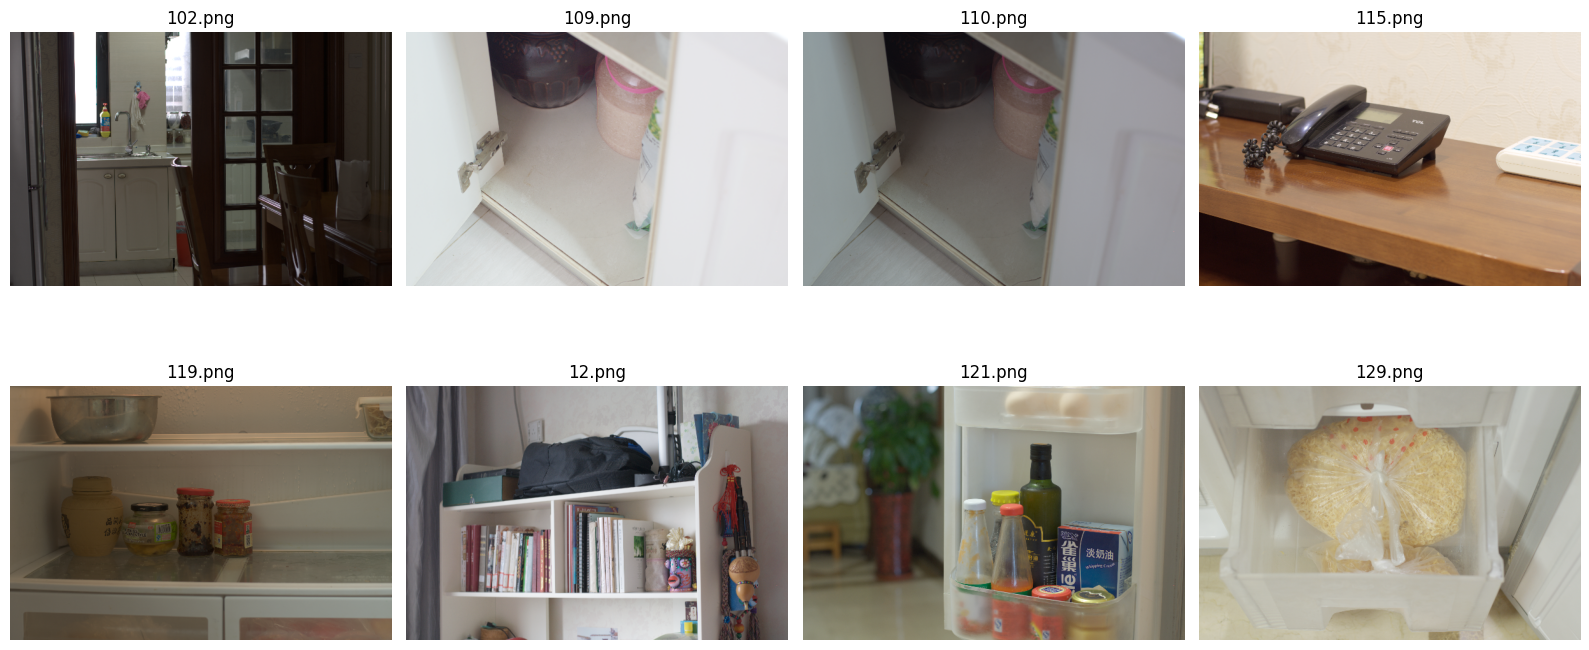

In [3]:
berkas = util.daftar_citra(FOLDER_CITRA)
if not berkas:
    raise RuntimeError(f"Tidak ada citra di {FOLDER_CITRA}")
stat = util.statistik_dataset(berkas)
print(f"{stat['jumlah']} citra ({stat['terbaca']} terbaca); minimal 200 untuk kelompok ini")
print("Lebar :", stat.get("lebar"))
print("Tinggi:", stat.get("tinggi"))
if stat["gagal"]:
    print("Gagal dibaca (hapus atau ganti):", *stat["gagal"][:10], sep="\n  ")
util.tampil(*[util.baca_citra(p) for p in berkas[:8]], judul=[p.name for p in berkas[:8]], kolom=4)

## 2. Cek anotasi

Pasangan citra gelap–terang sebagai referensi (mis. dataset LOL) dan foto malam sendiri. Foto sendiri tanpa pasangan dinilai dengan metrik tanpa referensi (NIQE/BRISQUE, opsional lewat paket pyiqa).

Kolom `anotasi.csv` (persis): `berkas_gelap, berkas_referensi, sumber`. Contoh baris ada di `data/format_anotasi.csv`.

In [4]:
KOLOM_BERKAS = ['berkas_gelap', 'berkas_referensi']
if BERKAS_ANOTASI.exists():
    anotasi = util.baca_anotasi(BERKAS_ANOTASI, KOLOM_ANOTASI)
    cek = util.cek_anotasi(anotasi, FOLDER_CITRA, KOLOM_BERKAS)
    print(len(anotasi), "baris anotasi")
    print("Disebut di anotasi tetapi berkasnya tidak ada:", cek["hilang"][:20])
    print("Citra belum beranotasi:", len(cek["tanpa_anotasi"]), cek["tanpa_anotasi"][:10])
else:
    print("anotasi.csv belum ada di", BERKAS_ANOTASI)

202 baris anotasi
Disebut di anotasi tetapi berkasnya tidak ada: []
Citra belum beranotasi: 0 []


## 3. Preprocessing

Saran untuk topik ini: resize seragam; konversi ruang warna ke LAB atau HSV; pemisahan kanal luminans dan warna.

Sel kode di bawah hanya **kerangka dummy**. Ganti dengan langkah preprocessing kelompok, lalu tulis **alasan setiap langkah** dan parameternya di sel markdown sesudahnya.

In [5]:
# ============================================================
# PREPROCESSING CITRA MALAM
# ============================================================

import cv2
import numpy as np


# Ukuran standar citra
UKURAN = (512, 512)


def praproses(citra):
    """
    Preprocessing citra malam:
    1. Resize citra menjadi 512 x 512
    2. Konversi ruang warna BGR ke LAB
    3. Memisahkan kanal L, A, dan B
    4. Normalisasi kanal L
    5. Menggabungkan kembali kanal LAB
    6. Mengubah kembali LAB ke BGR
    """

    # --------------------------------------------------------
    # 1. Resize
    # --------------------------------------------------------
    citra_resize = cv2.resize(
        citra,
        UKURAN,
        interpolation=cv2.INTER_AREA
    )

    # --------------------------------------------------------
    # 2. Konversi BGR -> LAB
    # --------------------------------------------------------
    lab = cv2.cvtColor(
        citra_resize,
        cv2.COLOR_BGR2LAB
    )

    # --------------------------------------------------------
    # 3. Pisahkan kanal L, A, dan B
    # --------------------------------------------------------
    L, A, B = cv2.split(lab)

    # --------------------------------------------------------
    # 4. Normalisasi kanal L
    # --------------------------------------------------------
    L_norm = cv2.normalize(
        L,
        None,
        alpha=0,
        beta=255,
        norm_type=cv2.NORM_MINMAX
    )

     # --------------------------------------------------------
    # 5. Gabungkan kembali kanal LAB
    # --------------------------------------------------------
    lab_preprocessed = cv2.merge(
        [L_norm, A, B]
    )

    # --------------------------------------------------------
    # 6. Konversi LAB -> BGR
    # --------------------------------------------------------
    hasil = cv2.cvtColor(
        lab_preprocessed,
        cv2.COLOR_LAB2BGR
    )

    return hasil


print("=" * 60)
print("PREPROCESSING CITRA MALAM")
print("=" * 60)
print(f"Ukuran standar citra : {UKURAN[0]} x {UKURAN[1]}")
print("Ruang warna          : BGR -> LAB")
print("Kanal yang digunakan : L, A, B")
print("Normalisasi          : Kanal L")
print("Status               : Siap digunakan")

PREPROCESSING CITRA MALAM
Ukuran standar citra : 512 x 512
Ruang warna          : BGR -> LAB
Kanal yang digunakan : L, A, B
Normalisasi          : Kanal L
Status               : Siap digunakan


In [6]:
# ============================================================
# UJI PREPROCESSING PADA 1 CITRA
# ============================================================

if not berkas:
    raise RuntimeError("Dataset citra tidak tersedia.")

# Ambil satu citra dari dataset
path_contoh = berkas[0]

# Baca citra
citra_asli = util.baca_citra(path_contoh)

if citra_asli is None:
    raise RuntimeError(
        f"Citra tidak dapat dibaca: {path_contoh}"
    )

# Jalankan preprocessing
citra_hasil = praproses(citra_asli)

# Tampilkan informasi hasil
print("=" * 60)
print("HASIL UJI PREPROCESSING")
print("=" * 60)

print(f"Nama file      : {path_contoh.name}")
print(
    f"Ukuran asli    : "
    f"{citra_asli.shape[1]} x {citra_asli.shape[0]}"
)
print(
    f"Ukuran hasil   : "
    f"{citra_hasil.shape[1]} x {citra_hasil.shape[0]}"
)
print(f"Tipe data hasil: {citra_hasil.dtype}")

print("Status         : Preprocessing berhasil diterapkan.")

HASIL UJI PREPROCESSING
Nama file      : 102.png
Ukuran asli    : 600 x 400
Ukuran hasil   : 512 x 512
Tipe data hasil: uint8
Status         : Preprocessing berhasil diterapkan.


langkah preprocessing
Preprocessing dilakukan untuk menyeragamkan ukuran citra dan memisahkan informasi luminans dengan informasi warna sebelum citra diproses menggunakan metode perbaikan citra.

Resize citra menjadi 512 × 512 piksel

Seluruh citra diubah menjadi ukuran 512 × 512 piksel agar memiliki ukuran yang seragam. Ukuran yang seragam memudahkan proses pengolahan, perbandingan, dan evaluasi antar citra. Parameter yang digunakan adalah ukuran 512 × 512 piksel dengan interpolasi INTER_AREA, yang sesuai digunakan untuk proses perubahan ukuran citra.

Konversi ruang warna BGR ke LAB

Citra dikonversi dari ruang warna BGR ke ruang warna LAB agar informasi kecerahan dan warna dapat dipisahkan. Ruang warna LAB memiliki tiga kanal, yaitu L yang merepresentasikan luminans atau tingkat kecerahan, sedangkan kanal A dan B merepresentasikan informasi warna. Pemisahan ini sesuai dengan karakteristik citra malam yang umumnya memiliki permasalahan pada tingkat pencahayaan.

Pemisahan kanal L, A, dan B

Setelah dikonversi ke LAB, citra dipisahkan menjadi kanal L, A, dan B. Kanal L digunakan sebagai komponen luminans yang nantinya dapat diproses oleh metode peningkatan citra seperti CLAHE, sedangkan kanal A dan B dipertahankan sebagai informasi warna. Pada tahap preprocessing ini tidak dilakukan peningkatan kecerahan atau perubahan warna agar proses enhancement dapat dilakukan secara terpisah pada tahap metode klasik.

Parameter preprocessing:

Ukuran citra: 512 × 512 piksel
Interpolasi resize: cv2.INTER_AREA
Konversi warna: BGR → LAB
Kanal luminans: L
Kanal warna: A dan B
Enhancement: tidak dilakukan pada tahap preprocessing

## 4. Gambar sebelum–sesudah

Sel ini menyimpan 12 contoh ke folder `figures/` di Drive. Unggah minimal 10 ke `outputs/figures/` di repo (lihat `PANDUAN.md`).

12 gambar di /content/drive/MyDrive/pcd2026-ti23pa-t2/figures


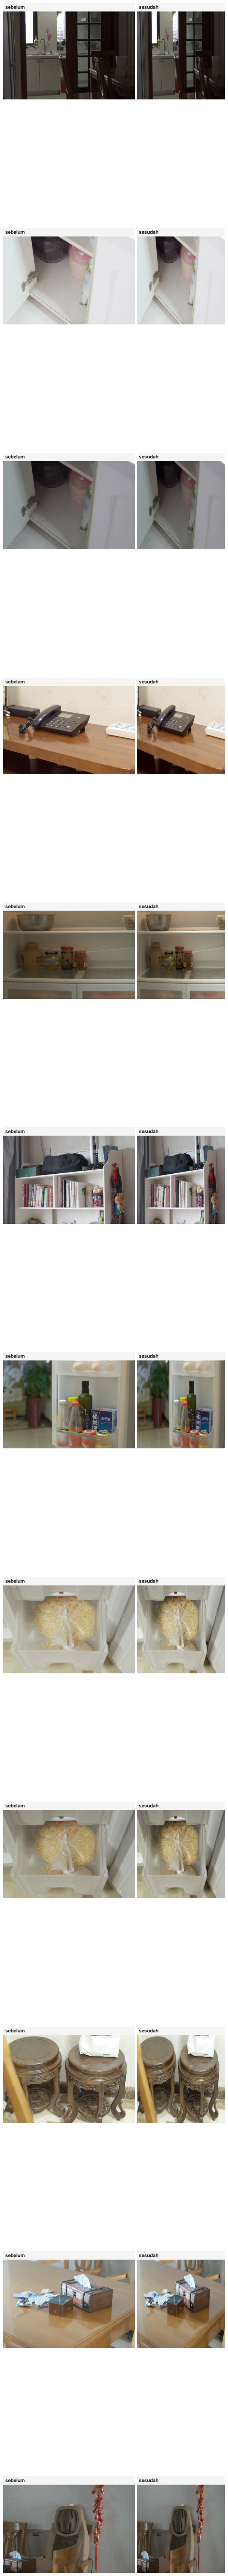

In [7]:
FOLDER_FIGUR.mkdir(parents=True, exist_ok=True)
for p in berkas[:12]:
    asli = util.ubah_ukuran_maks(util.baca_citra(p), 1024)
    util.simpan_sebelum_sesudah(asli, praproses(asli), FOLDER_FIGUR / f"pra_{p.stem}.png")
contoh = sorted(FOLDER_FIGUR.glob("pra_*.png"))[:15]
print(len(list(FOLDER_FIGUR.glob("pra_*.png"))), "gambar di", FOLDER_FIGUR)
util.tampil(*[util.baca_citra(f) for f in contoh], kolom=1, ukuran=7)

## Simpan ke GitHub

1. **Runtime → Restart session and run all**, pastikan tidak ada error.
2. **File → Save a copy in GitHub** → repo `Prodi-TI-IBIKesatuan/pcd2026-ti23pa-t2` → **branch Anda** (bukan `main`) → path tetap `notebooks/01_dataset_preprocessing.ipynb`.
3. Buka *pull request* ke `main` di github.com. Langkah lengkap: `PANDUAN.md`.